In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import Estimator, Sampler
from scipy.optimize import minimize

In [2]:
# 1. Problem Setup
n_particles = 3
p = 5   # Number of QAOA layers
h_list = [1, 2, -3]

# 2. Build cost Hamiltonian: H = \sum_{i=1}^{N-1} Z_i \otimes Z_{i+1} - \sum_{i=1}^{N} Z
def build_cost_ising(n_particles, h_list):
    pauli_list = []

    # Open chain interaction terms: -1.0 * Z_i \otimes Z_{i+1}
    for i in range(n_particles -1):
        label = ['I'] * n_particles
        label[i] = 'Z'
        label[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label)), -1.0))

    # Longitudinal magnetic field terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list)

cost_h = build_cost_ising(n_particles, h_list)

In [3]:
# 3. Building QAOA Quantum Circuit
def qaoa_circuit(params, p, cost_h, n_wires):
    """
    params is a 1D array of length 2*p: [gamma_0, ..., gamma_{p-1}, alpha_0, ..., alpha_{p-1}]
    """
    gammas = params[:p]
    alphas = params[p:]

    qc = QuantumCircuit(n_wires)

    # Initial states: Prepare |+> superposition on all qubits
    qc.h(range(n_wires))

    # p QAOA Layers
    for layer in range (p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # --- Cost Layer: exp(-i * gamma * H_C) ---
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            # Indices of qubits where Pauli Z acts
            active_qubits = [i for i, char in enumerate(reversed(pauli_string)) if char == 'Z']

            if len(active_qubits) == 1:
                # Single-qubit Z term: exp(-i * gamma * coeff * Z) -> RZ(2 * gamma * coeff)
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits[0], active_qubits[1]
                qc.rzz(2 * gamma * real_coeff, q0, q1)

        # --- Mixer Layer: exp(-i * alpha * H_M) ---
        # H_M = \sum X_i -> RX (2 * alpha) on all qubits
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

    return qc

In [4]:
# 4. Optimization Primitives & Cost Function
estimator = Estimator()
sampler = Sampler()

def cost_function(params):
    """Calculates <H_C> expectation value using Qiskit Estimator."""
    qc = qaoa_circuit(params, p, cost_h, n_particles)
    # Estimator evaluates expectation value of cost_h for circuit qc
    job = estimator.run(qc, cost_h)
    return job.result().values[0]

def probability_circuit(params):
    """Measures state probabilities using Qiskit Sampler."""
    qc = qaoa_circuit(params, p, cost_h, n_particles)
    qc.measure_all()
    job = sampler.run(qc)
    quasi_dists = job.result().quasi_dists[0]
    
    # Convert quasi-distribution dictionary to full 2^N probability array
    probs = np.zeros(2**n_particles)
    for state_int, prob in quasi_dists.items():
        probs[state_int] = prob
    return probs

# 5. QAOA Execution Routine
def QAOA_ising(initial_params, p, cost_h):
    # Optimize using SciPy's COBYLA (or L-BFGS-B)
    res = minimize(cost_function, initial_params, method='COBYLA', options={'maxiter': 200})
    
    optimal_params = res.x
    probs = probability_circuit(optimal_params)
    
    return probs, optimal_params

# Initial parameters array (p gammas followed by p alphas)
initial_params = np.ones(2 * p) * 0.5

# Run QAOA
probs, optimal_params = QAOA_ising(initial_params, p, cost_h)

# Display top measured binary states
print("Optimized Parameters (Gammas, Alphas):", optimal_params)
print("\nProbabilities per computational state:")
for state_int, prob in enumerate(probs):
    binary_str = format(state_int, f'0{n_particles}b')
    print(f"State |{binary_str}> : {prob * 100:.2f}%")

Optimized Parameters (Gammas, Alphas): [0.55223754 0.56667312 0.51382168 0.60894332 0.37274907 0.51100943
 1.59394664 0.50271708 0.37283321 0.51876399]

Probabilities per computational state:
State |000> : 11.62%
State |001> : 2.73%
State |010> : 1.37%
State |011> : 1.76%
State |100> : 63.57%
State |101> : 9.08%
State |110> : 2.25%
State |111> : 7.62%


Plotting Quantum Circuit Diagram...


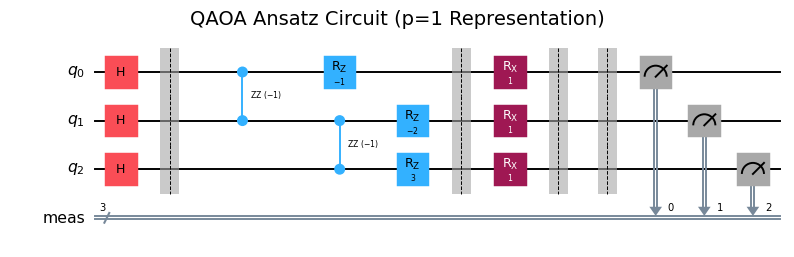

Running QAOA Optimizer...
Optimization finished!
Plotting Final Probabilities...


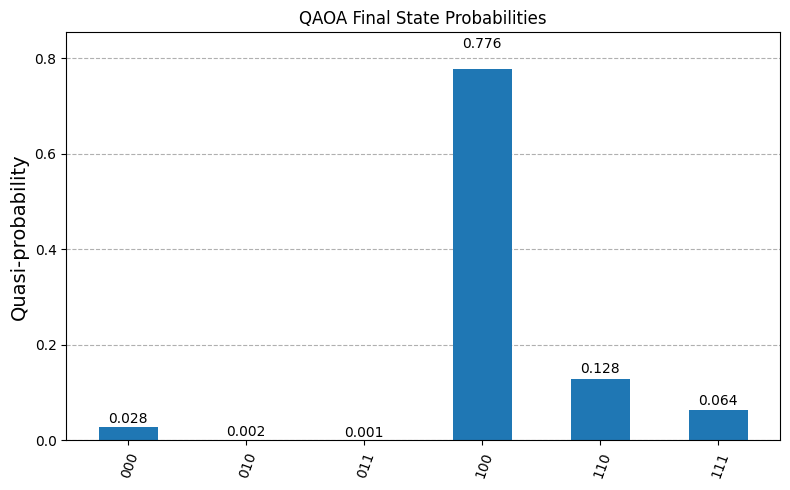

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import Sampler
from qiskit.visualization import plot_histogram

# 1. Problem Setup
n_particles = 3
p = 5  # Number of QAOA layers
h_list = [1, 2, -3]

# 2. Build Cost Hamiltonian
def build_cost_ising(n_particles, h_list):
    pauli_list = []
    
    # Open chain interaction terms: -1.0 * Z_i Z_{i+1}
    for i in range(n_particles - 1):
        label = ['I'] * n_particles
        label[i] = 'Z'
        label[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label)), -1.0))
        
    # Longitudinal magnetic field terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))
        
    return SparsePauliOp.from_list(pauli_list)

cost_h = build_cost_ising(n_particles, h_list)

# 3. Build QAOA Quantum Circuit Generator
def qaoa_circuit(params, p, cost_h, n_wires):
    gammas = params[:p]
    alphas = params[p:]
    
    qc = QuantumCircuit(n_wires)
    
    # Initial state: Prepare |+> superposition on all qubits
    qc.h(range(n_wires))
    qc.barrier()
    
    # p QAOA Layers
    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]
        
        # --- Cost Layer: exp(-i * gamma * H_C) ---
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            active_qubits = [i for i, char in enumerate(reversed(pauli_string)) if char == 'Z']
            
            if len(active_qubits) == 1:
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits[0], active_qubits[1]
                qc.rzz(2 * gamma * real_coeff, q0, q1)
                
        qc.barrier()
        
        # --- Mixer Layer: exp(-i * alpha * H_M) ---
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)
            
        qc.barrier()
            
    return qc

# Initialize Sampler primitive once globally
sampler = Sampler()

def get_probabilities(params):
    """Executes circuit and returns dictionary of probabilities."""
    qc = qaoa_circuit(params, p, cost_h, n_particles)
    qc.measure_all()
    job = sampler.run(qc)
    quasi_dists = job.result().quasi_dists[0]
    
    counts = {}
    for state_int, prob in quasi_dists.items():
        binary_str = format(state_int, f'0{n_particles}b')
        counts[binary_str] = prob
    return counts

def cost_function(params):
    """Computes exact expected energy directly from state probabilities."""
    probs = get_probabilities(params)
    
    # Calculate <H_C> = \sum_s P(s) * E(s)
    total_energy = 0.0
    for state_str, prob in probs.items():
        # state_str is string like '001', reverse for qubit index mapping
        z_vals = [1.0 if bit == '0' else -1.0 for bit in reversed(state_str)]
        
        # Open chain interaction energy
        energy = 0.0
        for i in range(n_particles - 1):
            energy += -1.0 * z_vals[i] * z_vals[i + 1]
            
        # Magnetic field energy
        for i in range(n_particles):
            energy += -h_list[i] * z_vals[i]
            
        total_energy += prob * energy
        
    return total_energy

# ==========================================
# STEP 1: PLOT CIRCUIT FIRST
# ==========================================
print("Plotting Quantum Circuit Diagram...")
initial_params = np.ones(2 * p) * 0.5

sample_qc = qaoa_circuit(initial_params, p=1, cost_h=cost_h, n_wires=n_particles)
sample_qc.measure_all()

# Create dedicated window for circuit
fig1 = plt.figure(figsize=(10, 4))
ax1 = fig1.add_subplot(111)
sample_qc.draw(output="mpl", ax=ax1)
ax1.set_title("QAOA Ansatz Circuit (p=1 Representation)", fontsize=14)
plt.draw()
plt.pause(0.1)

# ==========================================
# STEP 2: RUN OPTIMIZATION
# ==========================================
print("Running QAOA Optimizer...")
res = minimize(
    cost_function, initial_params, method="COBYLA", options={"maxiter": 100}
)
optimal_params = res.x
print("Optimization finished!")

# ==========================================
# STEP 3: PLOT HISTOGRAM (EXPLICIT AXES)
# ==========================================
print("Plotting Final Probabilities...")
prob_dict = get_probabilities(optimal_params)

# Create Figure 2 dedicated for the Histogram
fig_hist, ax_hist = plt.subplots(figsize=(8, 5))
plot_histogram(prob_dict, title="QAOA Final State Probabilities", ax=ax_hist)
fig_hist.tight_layout()

# Display the histogram window
plt.show()